# Auspify Technologies — Data Science Internship
## Netflix Data Analysis and Recommendation System

### Completed Tasks
1. Data Cleaning and Preprocessing
2. Exploratory Data Analysis
3. Content-Based Recommendation System
4. Trend Prediction Analysis

Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

# Task 1: Data Cleaning and Preprocessing

In [58]:
import pandas as pd
import numpy as np

# Load the internship dataset
df = pd.read_csv("/content/Dataset.csv")

# Display the first five records
display(df.head())

# Check dataset dimensions
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# Check column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Total rows: 8790
Total columns: 10
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate rows: 0


In [59]:
# TASK 1: Detailed Data Quality Check

print("Dataset Shape:", df.shape)

# 1. Check placeholder values
print("\n--- Placeholder Values ---")

for col in df.columns:
    count = df[col].astype(str).str.strip().str.lower().isin(
        ["not given", "unknown", "n/a", "na", "null", "none", ""]
    ).sum()

    if count > 0:
        print(f"{col}: {count} placeholder values")

# 2. Check unique values
print("\n--- Unique Values Per Column ---")
print(df.nunique())

# 3. Check date format
print("\n--- Sample date_added values ---")
print(df["date_added"].head(10))

# 4. Check categorical values
print("\n--- Type Distribution ---")
print(df["type"].value_counts())

print("\n--- Rating Values ---")
print(df["rating"].value_counts(dropna=False))

# 5. Check duplicate show IDs
print("\n--- Duplicate show_id values ---")
print(df["show_id"].duplicated().sum())


Dataset Shape: (8790, 10)

--- Placeholder Values ---
title: 1 placeholder values
director: 2588 placeholder values
country: 287 placeholder values

--- Unique Values Per Column ---
show_id         8790
type               2
title           8787
director        4528
country           86
date_added      1713
release_year      74
rating            14
duration         220
listed_in        513
dtype: int64

--- Sample date_added values ---
0    9/25/2021
1    9/24/2021
2    9/24/2021
3    9/22/2021
4    9/24/2021
5    9/24/2021
6    9/24/2021
7     5/1/2021
8    9/23/2021
9     5/1/2021
Name: date_added, dtype: object

--- Type Distribution ---
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

--- Rating Values ---
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: i

In [60]:
### Task 1 — Data Cleaning and Preprocessing

import pandas as pd
import numpy as np

# Create a working copy of the original dataset
clean_df = df.copy()

print("Original dataset shape:", clean_df.shape)

# 1. Remove extra spaces from text columns
text_columns = clean_df.select_dtypes(include="object").columns

for col in text_columns:
    clean_df[col] = clean_df[col].str.strip()

# 2. Standardize placeholder values
placeholders = ["Not Given", "Unknown", "N/A", "NA", "None", ""]

for col in text_columns:
    clean_df[col] = clean_df[col].replace(placeholders, np.nan)

# 3. Check missing values after placeholder handling
print("\nMissing values after placeholder handling:")
print(clean_df.isnull().sum())

# 4. Remove exact duplicate records, if any
duplicates_before = clean_df.duplicated().sum()
clean_df = clean_df.drop_duplicates()

print("\nDuplicate rows found:", duplicates_before)
print("Shape after removing duplicates:", clean_df.shape)

# 5. Convert date_added to a proper datetime format
clean_df["date_added"] = pd.to_datetime(
    clean_df["date_added"],
    format="mixed",
    errors="coerce"
)

# 6. Standardize categorical text values
for col in ["type", "rating"]:
    clean_df[col] = clean_df[col].str.strip()

# 7. Validate show_id uniqueness
print("\nDuplicate show IDs:", clean_df["show_id"].duplicated().sum())

# 8. Display final data quality summary
print("\nFinal dataset shape:", clean_df.shape)

print("\nFinal data types:")
print(clean_df.dtypes)

print("\nFinal missing values:")
print(clean_df.isnull().sum())

# 9. Save the cleaned dataset
clean_df.to_csv("/content/netflix_cleaned.csv", index=False)

print("\nCleaned dataset saved as netflix_cleaned.csv")

display(clean_df.head())



Original dataset shape: (8790, 10)

Missing values after placeholder handling:
show_id            0
type               0
title              1
director        2588
country          287
date_added         0
release_year       0
rating             0
duration           0
listed_in          0
dtype: int64

Duplicate rows found: 0
Shape after removing duplicates: (8790, 10)

Duplicate show IDs: 0

Final dataset shape: (8790, 10)

Final data types:
show_id                 object
type                    object
title                   object
director                object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
dtype: object

Final missing values:
show_id            0
type               0
title              1
director        2588
country          287
date_added         0
release_year       0
rating             0
duration           0
listed_in         

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [61]:
# Final validation for Task 1

print("FINAL QUALITY CHECK")
print("-" * 35)

print("Total records:", len(clean_df))
print("Missing titles:", clean_df["title"].isna().sum())
print("Missing directors:", clean_df["director"].isna().sum())
print("Missing countries:", clean_df["country"].isna().sum())
print("Invalid or missing dates:", clean_df["date_added"].isna().sum())
print("Duplicate rows:", clean_df.duplicated().sum())
print("Duplicate IDs:", clean_df["show_id"].duplicated().sum())

print("\nFile ready for submission:")
print("/content/netflix_cleaned.csv")

FINAL QUALITY CHECK
-----------------------------------
Total records: 8790
Missing titles: 1
Missing directors: 2588
Missing countries: 287
Invalid or missing dates: 0
Duplicate rows: 0
Duplicate IDs: 0

File ready for submission:
/content/netflix_cleaned.csv


# Task 2: Exploratory Data Analysis

Content Type Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Percentage Distribution:
type
Movie      69.69
TV Show    30.31
Name: count, dtype: float64


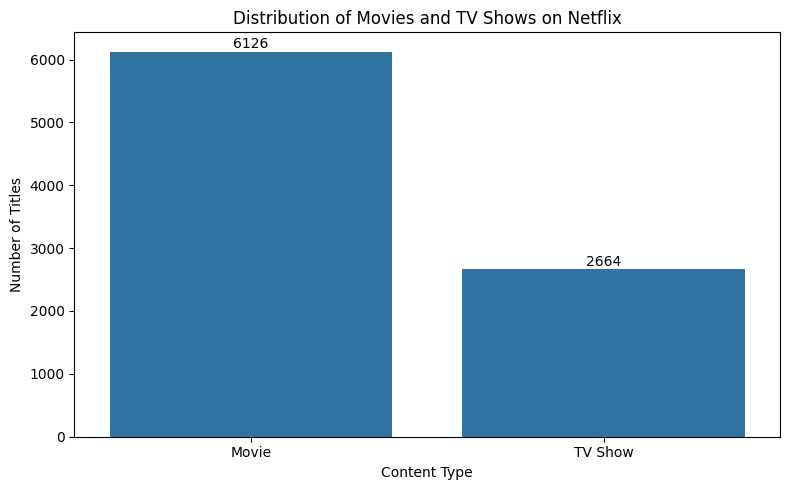

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

# Task 2: Exploratory Data Analysis

type_counts = clean_df["type"].value_counts()

print("Content Type Distribution:")
print(type_counts)

type_percentages = (type_counts / len(clean_df)) * 100

print("\nPercentage Distribution:")
print(type_percentages.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(x=type_counts.index, y=type_counts.values)

plt.title("Distribution of Movies and TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

for i, value in enumerate(type_counts.values):
    plt.text(i, value + 50, str(value), ha="center")

plt.tight_layout()
plt.show()

Earliest release year: 1925
Latest release year: 2021


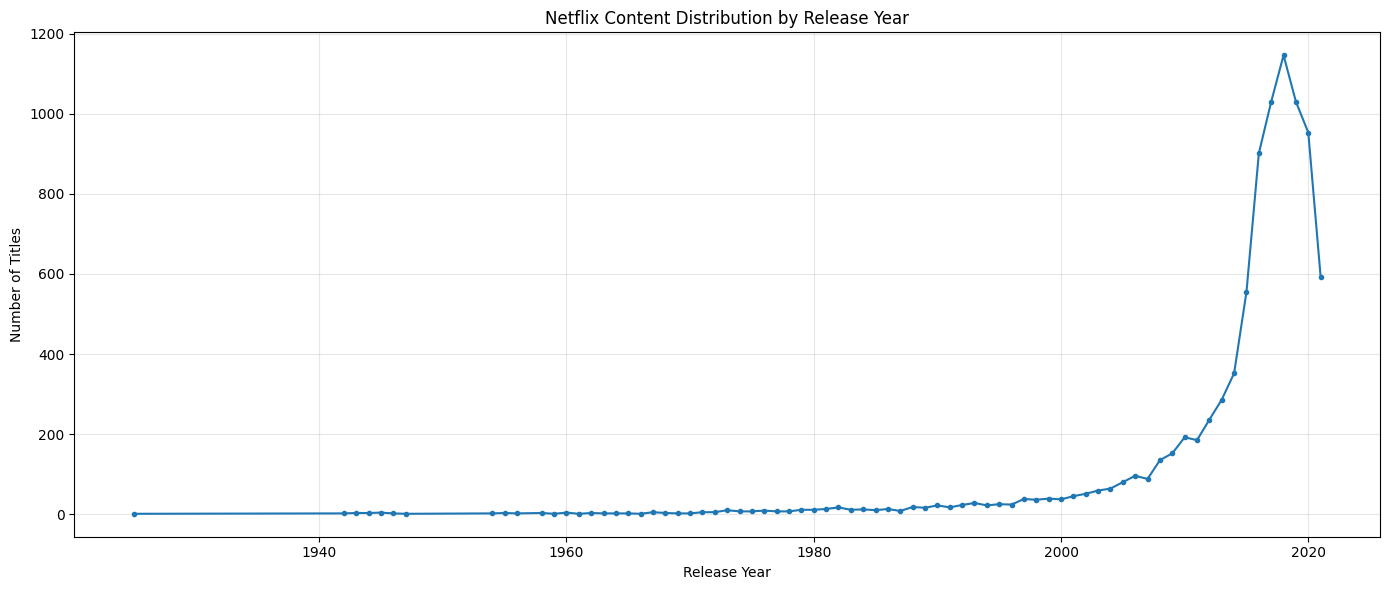


Top 10 Release Years:
release_year
2018    1146
2017    1030
2019    1030
2020     953
2016     901
2021     592
2015     555
2014     352
2013     286
2012     236
Name: count, dtype: int64


In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

# Task 2: Release Year Analysis

year_counts = clean_df["release_year"].value_counts().sort_index()

print("Earliest release year:", clean_df["release_year"].min())
print("Latest release year:", clean_df["release_year"].max())

# Count titles released each year
yearly_titles = clean_df["release_year"].value_counts().sort_index()

# Plot yearly content distribution
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_titles.index,
    yearly_titles.values,
    marker="o",
    markersize=3
)

plt.title("Netflix Content Distribution by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display the 10 years with the most titles
print("\nTop 10 Release Years:")
print(yearly_titles.sort_values(ascending=False).head(10))

Top 10 Countries by Title Associations:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


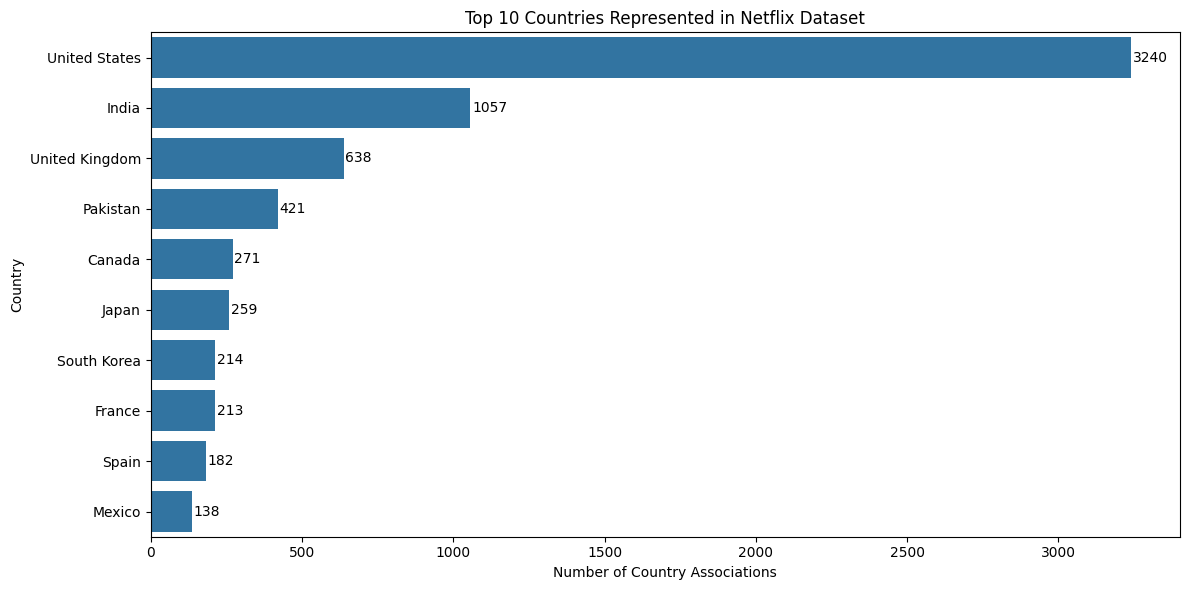

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Task 2: Top 10 Countries Analysis

country_data = clean_df["country"].dropna()

# Split entries containing multiple countries
country_list = country_data.str.split(",").explode().str.strip()

# Remove any empty country names
country_list = country_list[country_list != ""]

# Count titles associated with each country
top_countries = country_list.value_counts().head(10)

print("Top 10 Countries by Title Associations:")
print(top_countries)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries Represented in Netflix Dataset")
plt.xlabel("Number of Country Associations")
plt.ylabel("Country")

for i, value in enumerate(top_countries.values):
    plt.text(value + 5, i, str(value), va="center")

plt.tight_layout()
plt.show()

Top 10 Genres/Categories:
listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


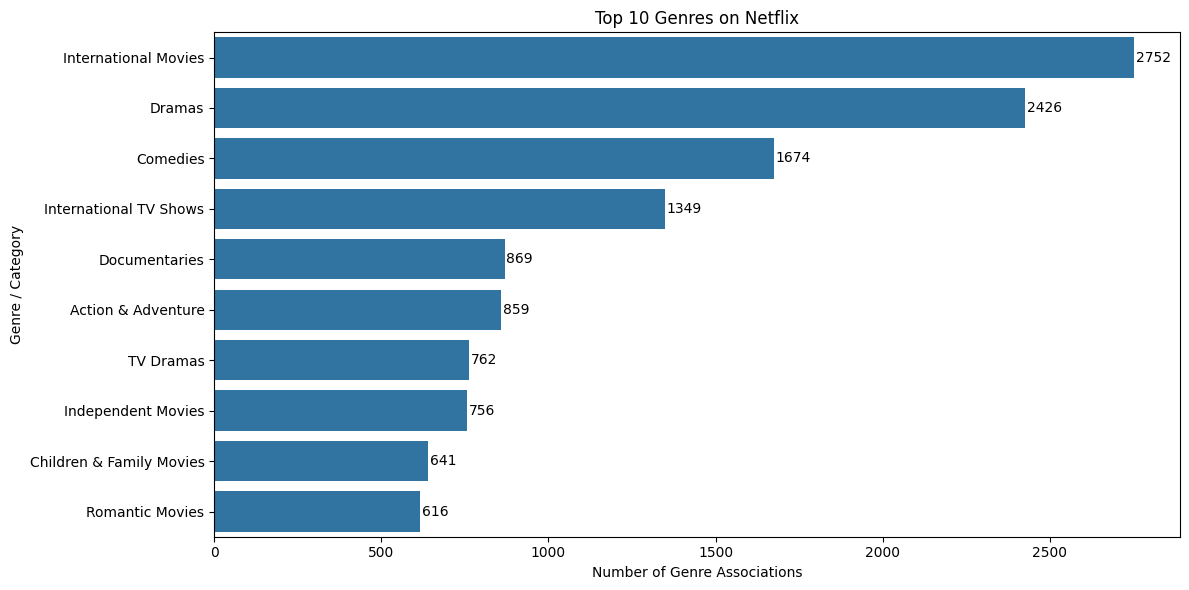

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

# Task 2: Genre Analysis

# Split genres/categories into individual entries
genre_data = clean_df["listed_in"].dropna()

genre_list = (
    genre_data
    .str.split(",")
    .explode()
    .str.strip()
)

# Remove empty entries
genre_list = genre_list[genre_list != ""]

# Find the top 10 genres
top_genres = genre_list.value_counts().head(10)

print("Top 10 Genres/Categories:")
print(top_genres)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Genre Associations")
plt.ylabel("Genre / Category")

for i, value in enumerate(top_genres.values):
    plt.text(value + 5, i, str(value), va="center")

plt.tight_layout()
plt.show()

# Task 3: Recommendation System

In [66]:
# Task 3: Recommendation System

import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Recommendation System libraries loaded successfully!")

print("\nDataset columns:")
print(clean_df.columns.tolist())

print("\nAvailable titles:", clean_df["title"].nunique())

Recommendation System libraries loaded successfully!

Dataset columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Available titles: 8785


In [67]:
# TASK 3: Netflix Recommendation System

import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Create a separate dataset for recommendations
rec_df = clean_df.copy()

# Remove titles that are missing
rec_df = rec_df.dropna(subset=["title"]).copy()

# Normalize title text for searching
rec_df["search_title"] = rec_df["title"].astype(str).str.strip().str.lower()

# Replace missing metadata with empty strings
metadata_columns = ["type", "director", "country", "rating", "listed_in"]

for col in metadata_columns:
    rec_df[col] = rec_df[col].fillna("").astype(str)

# Combine useful metadata into one feature
rec_df["features"] = (
    rec_df["type"] + " " +
    rec_df["director"] + " " +
    rec_df["country"] + " " +
    rec_df["rating"] + " " +
    rec_df["listed_in"]
)

# Convert text features into TF-IDF vectors
tfidf = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf.fit_transform(rec_df["features"])

print("Recommendation model created successfully!")
print("Available titles:", len(rec_df))
print("TF-IDF matrix shape:", tfidf_matrix.shape)

Recommendation model created successfully!
Available titles: 8789
TF-IDF matrix shape: (8789, 6566)


In [68]:
# Function to recommend similar titles

def recommend_titles(title, number_of_recommendations=5):

    search_name = title.strip().lower()

    matches = rec_df.index[
        rec_df["search_title"] == search_name
    ].tolist()

    if not matches:
        print(f"Title '{title}' was not found in the dataset.")
        print("Please enter a title that exists in the dataset.")
        return pd.DataFrame()

    # Use the first matching title
    title_index = matches[0]

    # Calculate cosine similarity with all titles
    similarity_scores = cosine_similarity(
        tfidf_matrix[title_index],
        tfidf_matrix
    ).flatten()

    # Sort titles by similarity, highest first
    ranked_indices = similarity_scores.argsort()[::-1]

    # Exclude the selected title itself
    ranked_indices = [
        idx for idx in ranked_indices
        if idx != title_index
    ]

    # Select top recommendations
    top_indices = ranked_indices[:number_of_recommendations]

    recommendations = rec_df.iloc[top_indices][
        ["title", "type", "release_year", "listed_in"]
    ].copy()

    recommendations["similarity_score"] = [
        round(float(similarity_scores[idx]), 3)
        for idx in top_indices
    ]

    return recommendations.reset_index(drop=True)


# Test the recommendation system
recommend_titles("Breaking Bad", 5)

,title,type,release_year,listed_in,similarity_score
0,Rising Phoenix,Movie,2020,"Documentaries, International Movies, Sports Mo...",0.787
1,Night on Earth: Shot in the Dark,Movie,2020,Movies,0.758
2,Diana: In Her Own Words,Movie,2017,"Documentaries, International Movies",0.625
3,Antoine Griezmann: The Making of a Legend,Movie,2019,"Documentaries, International Movies, Sports Mo...",0.615
4,Roll With Me,Movie,2017,"Documentaries, Sports Movies",0.615


In [69]:
# Task 3: Recommendation System Testing

test_titles = ["Breaking Bad", "Stranger Things", "The Crown"]

for title in test_titles:
    print("\n" + "=" * 50)
    print("Recommendations for:", title)
    print("=" * 50)

    results = recommend_titles(title, 5)

    if not results.empty:
        display(results)


Recommendations for: Breaking Bad


,title,type,release_year,listed_in,similarity_score
0,Rising Phoenix,Movie,2020,"Documentaries, International Movies, Sports Mo...",0.787
1,Night on Earth: Shot in the Dark,Movie,2020,Movies,0.758
2,Diana: In Her Own Words,Movie,2017,"Documentaries, International Movies",0.625
3,Antoine Griezmann: The Making of a Legend,Movie,2019,"Documentaries, International Movies, Sports Mo...",0.615
4,Roll With Me,Movie,2017,"Documentaries, Sports Movies",0.615



Recommendations for: Stranger Things


,title,type,release_year,listed_in,similarity_score
0,Medal of Honor,TV Show,2018,"Docuseries, TV Dramas",1.00
1,Follow This,TV Show,2018,Docuseries,0.94
2,Song Exploder,TV Show,2020,Docuseries,0.94
3,Chicken Soup for the Soul's Being Dad,TV Show,2018,Docuseries,0.94
4,Rapture,TV Show,2018,Docuseries,0.94



Recommendations for: The Crown


,title,type,release_year,listed_in,similarity_score
0,Hannibal,TV Show,2015,"TV Horror, TV Mysteries, TV Thrillers",1.000
1,The Haunting of Hill House,TV Show,2018,"TV Dramas, TV Horror, TV Mysteries",0.917
2,The Haunting of Bly Manor,TV Show,2020,"TV Dramas, TV Horror, TV Mysteries",0.917
3,Ratched,TV Show,2020,"TV Dramas, TV Horror, TV Mysteries",0.917
4,Brand New Cherry Flavor,TV Show,2021,"TV Dramas, TV Horror, TV Mysteries",0.917


In [70]:
# TASK 3: Improved Recommendation System

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Prepare data and reset index
rec_df = clean_df.dropna(subset=["title"]).copy()
rec_df = rec_df.reset_index(drop=True)

# Fill missing metadata
for col in ["type", "director", "country", "listed_in"]:
    rec_df[col] = rec_df[col].fillna("").astype(str)

# Normalize titles
rec_df["search_title"] = rec_df["title"].str.strip().str.lower()

# Create weighted metadata features
def create_features(row):
    genres = row["listed_in"].replace(",", " ").lower()
    director = row["director"].replace(" ", "_").lower()
    content_type = row["type"].replace(" ", "_").lower()

    return (
        (genres + " ") * 4 +
        (director + " ") * 2 +
        content_type
    )

rec_df["features"] = rec_df.apply(create_features, axis=1)

# TF-IDF transformation
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(rec_df["features"])

# Improved recommendation function
def recommend_titles(title, n=5):
    matches = rec_df.index[
        rec_df["search_title"] == title.strip().lower()
    ].tolist()

    if not matches:
        print("Title not found:", title)
        return pd.DataFrame()

    idx = matches[0]

    scores = cosine_similarity(
        tfidf_matrix[idx],
        tfidf_matrix
    ).flatten()

    # Exclude the selected title
    scores[idx] = -1

    # Keep same content type
    same_type = (
        rec_df["type"].values == rec_df.iloc[idx]["type"]
    )

    scores[~same_type] = -1

    # Get highest-scoring titles
    top_indices = scores.argsort()[::-1]
    top_indices = [
        i for i in top_indices
        if scores[i] > 0
    ][:n]

    result = rec_df.iloc[top_indices][
        ["title", "type", "release_year", "listed_in"]
    ].copy()

    result["similarity_score"] = [
        round(float(scores[i]), 3)
        for i in top_indices
    ]

    return result.reset_index(drop=True)

print("Improved Recommendation System Ready!")

# Test again
for title in ["Breaking Bad", "Stranger Things", "The Crown"]:
    print("\nRecommendations for:", title)
    display(recommend_titles(title))

Improved Recommendation System Ready!

Recommendations for: Breaking Bad


,title,type,release_year,listed_in,similarity_score
0,The Assassination of Gianni Versace,TV Show,2018,"Crime TV Shows, TV Dramas, TV Thrillers",1.0
1,Designated Survivor,TV Show,2019,"Crime TV Shows, TV Dramas, TV Thrillers",1.0
2,Dare Me,TV Show,2019,"Crime TV Shows, TV Dramas, TV Thrillers",1.0
3,Ozark,TV Show,2020,"Crime TV Shows, TV Dramas, TV Thrillers",1.0
4,The Blacklist,TV Show,2019,"Crime TV Shows, TV Dramas, TV Thrillers",1.0



Recommendations for: Stranger Things


,title,type,release_year,listed_in,similarity_score
0,Nightflyers,TV Show,2018,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",1.000
1,Chilling Adventures of Sabrina,TV Show,2020,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",1.000
2,Helix,TV Show,2015,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",1.000
3,The Vampire Diaries,TV Show,2016,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",0.929
4,The OA,TV Show,2019,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",0.929



Recommendations for: The Crown


,title,type,release_year,listed_in,similarity_score
0,Black Earth Rising,TV Show,2018,"British TV Shows, International TV Shows, TV D...",1.0
1,The A List,TV Show,2021,"British TV Shows, International TV Shows, TV D...",1.0
2,The English Game,TV Show,2020,"British TV Shows, International TV Shows, TV D...",1.0
3,Leila,TV Show,2019,"British TV Shows, International TV Shows, TV D...",1.0
4,Requiem,TV Show,2018,"British TV Shows, International TV Shows, TV D...",1.0


In [71]:
# Task 3: Genre Overlap Evaluation

test_titles = ["Breaking Bad", "Stranger Things", "The Crown"]

for title in test_titles:
    input_row = rec_df[
        rec_df["search_title"] == title.lower()
    ].iloc[0]

    input_genres = set(
        g.strip().lower()
        for g in input_row["listed_in"].split(",")
    )

    results = recommend_titles(title, 5)

    print("\nTitle:", title)
    print("Input genres:", input_row["listed_in"])

    for _, row in results.iterrows():
        recommended_genres = set(
            g.strip().lower()
            for g in row["listed_in"].split(",")
        )

        overlap = len(input_genres & recommended_genres)
        total = len(input_genres | recommended_genres)

        score = overlap / total if total else 0

        print(
            row["title"],
            "| Genre overlap score:",
            round(score, 3)
        )


Title: Breaking Bad
Input genres: Crime TV Shows, TV Dramas, TV Thrillers
The Assassination of Gianni Versace | Genre overlap score: 1.0
Designated Survivor | Genre overlap score: 1.0
Dare Me | Genre overlap score: 1.0
Ozark | Genre overlap score: 1.0
The Blacklist | Genre overlap score: 1.0

Title: Stranger Things
Input genres: TV Horror, TV Mysteries, TV Sci-Fi & Fantasy
Nightflyers | Genre overlap score: 1.0
Chilling Adventures of Sabrina | Genre overlap score: 1.0
Helix | Genre overlap score: 1.0
The Vampire Diaries | Genre overlap score: 0.5
The OA | Genre overlap score: 0.5

Title: The Crown
Input genres: British TV Shows, International TV Shows, TV Dramas
Black Earth Rising | Genre overlap score: 1.0
The A List | Genre overlap score: 1.0
The English Game | Genre overlap score: 1.0
Leila | Genre overlap score: 1.0
Requiem | Genre overlap score: 1.0


# Task 4: Trend Prediction Analysis

In [72]:
# TASK 4: Trend Prediction Analysis
# Step 1: Prepare yearly release data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

trend_df = clean_df.copy()

# Convert release year to numeric
trend_df["release_year"] = pd.to_numeric(
    trend_df["release_year"],
    errors="coerce"
)

# Remove invalid release years
trend_df = trend_df.dropna(subset=["release_year"])

# Count titles by release year
yearly_data = (
    trend_df.groupby("release_year")
    .size()
    .reset_index(name="title_count")
)

yearly_data = yearly_data.sort_values("release_year")

print("Yearly Trend Data Prepared Successfully!")
print("\nTotal years:", len(yearly_data))

print("\nLast 15 Years:")
display(yearly_data.tail(15))

# Save trend dataset
yearly_data.to_csv(
    "/content/netflix_yearly_trends.csv",
    index=False
)

print("\nYearly trend CSV saved successfully!")

Yearly Trend Data Prepared Successfully!

Total years: 74

Last 15 Years:


,release_year,title_count
59,2007,88
60,2008,135
61,2009,152
62,2010,192
63,2011,185
64,2012,236
65,2013,286
66,2014,352
67,2015,555
68,2016,901



Yearly trend CSV saved successfully!


Trend Prediction Model Trained Successfully!

Model Evaluation:
Mean Absolute Error (MAE): 479.22
Root Mean Squared Error (RMSE): 562.59

Actual vs Predicted:


,Year,Actual Titles,Predicted Titles
0,2019,1030,1205
1,2020,953,1338
2,2021,592,1470


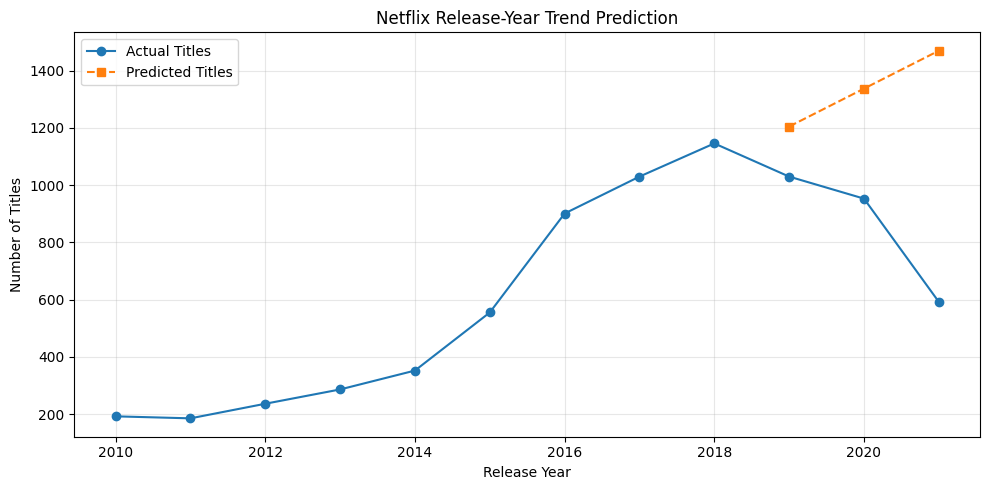

In [73]:
# TASK 4: Train and Evaluate Trend Prediction Model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Select recent historical years
model_data = yearly_data[
    (yearly_data["release_year"] >= 2010) &
    (yearly_data["release_year"] <= 2021)
].copy()

# Chronological train-test split
train_data = model_data[
    model_data["release_year"] <= 2018
]

test_data = model_data[
    model_data["release_year"] >= 2019
]

X_train = train_data[["release_year"]]
y_train = train_data["title_count"]

X_test = test_data[["release_year"]]
y_test = test_data["title_count"]

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test years
predictions = model.predict(X_test)
predictions = np.maximum(predictions, 0)

# Calculate errors
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Trend Prediction Model Trained Successfully!")

print("\nModel Evaluation:")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Year": X_test["release_year"].values,
    "Actual Titles": y_test.values,
    "Predicted Titles": np.round(predictions).astype(int)
})

print("\nActual vs Predicted:")
display(comparison)

# Plot predictions
plt.figure(figsize=(10, 5))

plt.plot(
    model_data["release_year"],
    model_data["title_count"],
    marker="o",
    label="Actual Titles"
)

plt.plot(
    X_test["release_year"],
    predictions,
    marker="s",
    linestyle="--",
    label="Predicted Titles"
)

plt.title("Netflix Release-Year Trend Prediction")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [74]:
# TASK 4: Compare Forecasting Models

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

# Prepare training and testing data
train = model_data[
    model_data["release_year"] <= 2018
]

test = model_data[
    model_data["release_year"] >= 2019
]

X_train = train[["release_year"]]
y_train = train["title_count"]

X_test = test[["release_year"]]
y_test = test["title_count"]

# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_pred = np.maximum(
    linear_model.predict(X_test), 0
)

# Model 2: Random Forest Regression
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = np.maximum(
    rf_model.predict(X_test), 0
)

# Compare results
comparison_models = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, rf_pred)
    ]
})

print("MODEL COMPARISON")
display(comparison_models.round(2))

# Actual vs predicted values
results = pd.DataFrame({
    "Year": X_test["release_year"].values,
    "Actual": y_test.values,
    "Linear Regression": np.round(linear_pred).astype(int),
    "Random Forest": np.round(rf_pred).astype(int)
})

print("\nPREDICTION COMPARISON")
display(results)

MODEL COMPARISON


,Model,MAE
0,Linear Regression,479.22
1,Random Forest,237.82



PREDICTION COMPARISON


,Year,Actual,Linear Regression,Random Forest
0,2019,1030,1205,1096
1,2020,953,1338,1096
2,2021,592,1470,1096


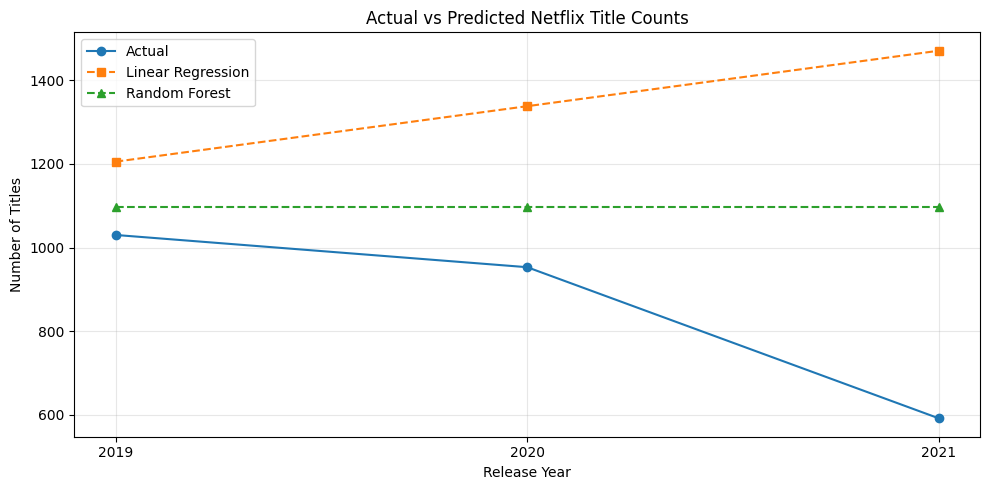

ILLUSTRATIVE FUTURE FORECAST


,Year,Linear Regression,Random Forest
0,2022,1603,1096
1,2023,1735,1096
2,2024,1868,1096
3,2025,2000,1096


Forecast CSV saved successfully!


In [75]:
# TASK 4: Final Visualization and Experimental Forecast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Historical test comparison
plt.figure(figsize=(10, 5))

plt.plot(
    X_test["release_year"],
    y_test,
    marker="o",
    label="Actual"
)

plt.plot(
    X_test["release_year"],
    linear_pred,
    marker="s",
    linestyle="--",
    label="Linear Regression"
)

plt.plot(
    X_test["release_year"],
    rf_pred,
    marker="^",
    linestyle="--",
    label="Random Forest"
)

plt.title("Actual vs Predicted Netflix Title Counts")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks([2019, 2020, 2021])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Illustrative future predictions
future_years = pd.DataFrame({
    "release_year": [2022, 2023, 2024, 2025]
})

future_linear = np.maximum(
    linear_model.predict(future_years), 0
)

future_rf = np.maximum(
    rf_model.predict(future_years), 0
)

future_results = pd.DataFrame({
    "Year": future_years["release_year"],
    "Linear Regression": np.round(future_linear).astype(int),
    "Random Forest": np.round(future_rf).astype(int)
})

print("ILLUSTRATIVE FUTURE FORECAST")
display(future_results)

future_results.to_csv(
    "/content/netflix_future_forecast.csv",
    index=False
)

print("Forecast CSV saved successfully!")

In [77]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

print("Task 5: ML Classification Model")
print("All libraries imported successfully!")

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("\nDataset Shape:", df.shape)
print("\nAvailable Columns:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())


Task 5: ML Classification Model
All libraries imported successfully!


Saving Dataset.csv to Dataset (2).csv

Dataset Shape: (8790, 10)

Available Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

First 5 Records:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [ ]:

# Task 5 - Step 2: Data Preprocessing

# Create a separate copy
ml_df = df.copy()

# Select useful features
ml_df["date_added"] = pd.to_datetime(
    ml_df["date_added"], errors="coerce"
)

ml_df["year_added"] = ml_df["date_added"].dt.year

features = [
    "release_year",
    "country",
    "rating",
    "year_added"
]

target = "type"

# Keep selected columns
ml_df = ml_df[features + [target]]

# Check missing values
print("Missing Values:")
print(ml_df.isnull().sum())

# Check target distribution
print("\nContent Type Distribution:")
print(ml_df["type"].value_counts())

# Preview prepared data
print("\nPrepared Dataset:")
display(ml_df.head())

print("\nDataset Shape:", ml_df.shape)



In [78]:

# Task 5 - Step 3: Train-Test Split and Encoding

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Separate features and target
X = ml_df.drop("type", axis=1)
y = ml_df["type"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define column types
numeric_features = ["release_year", "year_added"]
categorical_features = ["country", "rating"]

# Preprocessing for numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Train-Test Split Successful!")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

print("\nPreprocessing Pipeline Created Successfully!")


Train-Test Split Successful!
Training Data: (7032, 4)
Testing Data: (1758, 4)

Training Target Distribution:
type
Movie      4901
TV Show    2131
Name: count, dtype: int64

Testing Target Distribution:
type
Movie      1225
TV Show     533
Name: count, dtype: int64

Preprocessing Pipeline Created Successfully!


In [79]:

# Task 5 - Step 4: Train ML Classification Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Model 1: Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train Logistic Regression
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

# Model 2: Random Forest
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Random Forest
random_forest_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

print("\nBoth ML Models Trained Successfully!")


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Model Trained Successfully!
Random Forest Model Trained Successfully!

Both ML Models Trained Successfully!


In [80]:

# Fix Logistic Regression Convergence Warning

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Updated numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Updated preprocessing pipeline
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Rebuild Logistic Regression model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train again
logistic_model.fit(X_train, y_train)

print("Logistic Regression Retrained Successfully!")
print("Numerical Features Scaled Successfully!")
print("Convergence Status:",
      logistic_model.named_steps["classifier"].n_iter_[0] < 2000)


Logistic Regression Retrained Successfully!
Numerical Features Scaled Successfully!
Convergence Status: True


In [81]:

# Task 5 - Step 5: Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predictions
logistic_pred = logistic_model.predict(X_test)
rf_pred = random_forest_model.predict(X_test)

# Evaluation function
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, average="weighted",
            zero_division=0
        )
    }

# Compare both models
results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression", y_test, logistic_pred
    ),
    evaluate_model(
        "Random Forest", y_test, rf_pred
    )
])

print("ML Model Performance Comparison:")
display(results.round(4))

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, logistic_pred))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_pred))

print("\nBest Model by Accuracy:")
print(results.loc[results["Accuracy"].idxmax(), "Model"])


ML Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7844,0.7768,0.7844,0.7680
1,Random Forest,0.7878,0.7808,0.7878,0.7823



Logistic Regression Classification Report:
              precision    recall  f1-score   support

       Movie       0.80      0.93      0.86      1225
     TV Show       0.73      0.46      0.56       533

    accuracy                           0.78      1758
   macro avg       0.76      0.69      0.71      1758
weighted avg       0.78      0.78      0.77      1758


Random Forest Classification Report:
              precision    recall  f1-score   support

       Movie       0.83      0.88      0.85      1225
     TV Show       0.68      0.57      0.62       533

    accuracy                           0.79      1758
   macro avg       0.75      0.73      0.74      1758
weighted avg       0.78      0.79      0.78      1758


Best Model by Accuracy:
Random Forest


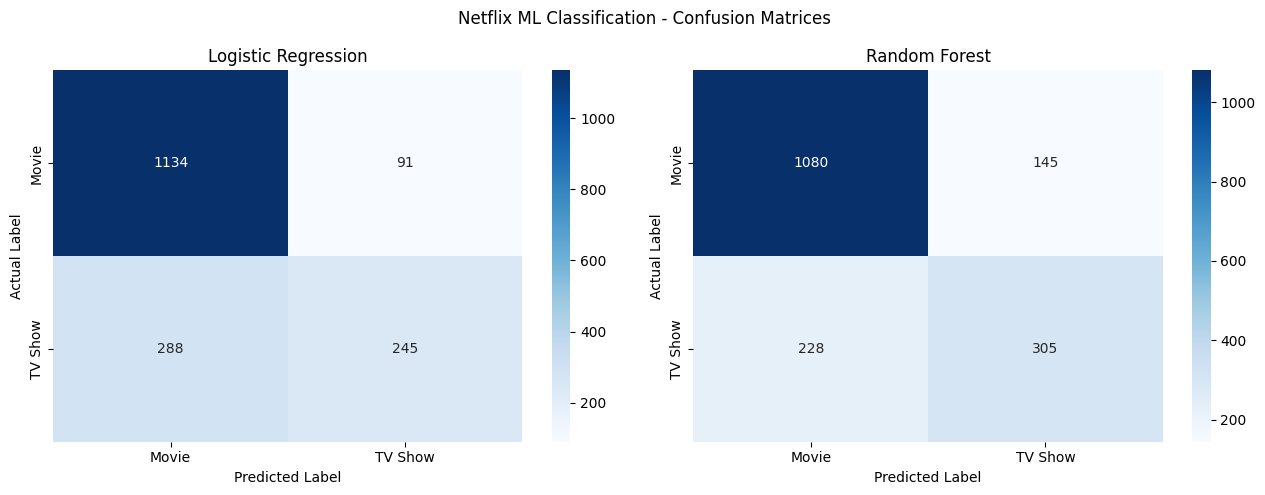

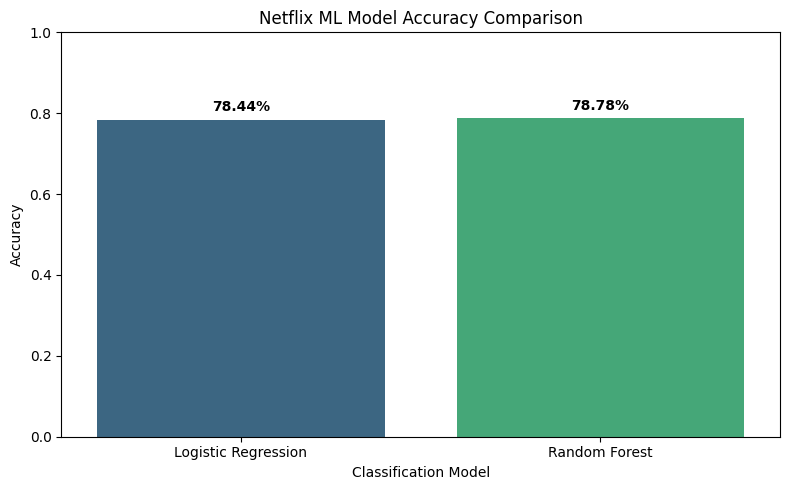

Both ML Visualization Graphs Created Successfully!


In [82]:

# Task 5 - Step 6: Model Visualization

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Logistic Regression", logistic_pred),
    ("Random Forest", rf_pred)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["Movie", "TV Show"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Movie", "TV Show"],
        yticklabels=["Movie", "TV Show"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Netflix ML Classification - Confusion Matrices")
plt.tight_layout()
plt.savefig("task5_confusion_matrices.png", dpi=300)
plt.show()

# Accuracy comparison
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=results,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Netflix ML Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Classification Model")
plt.ylim(0, 1)

for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height * 100:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig("task5_accuracy_comparison.png", dpi=300)
plt.show()

print("Both ML Visualization Graphs Created Successfully!")


In [84]:

# Task 5 - Step 7: Save ML Model and Results

import joblib
import pandas as pd
from sklearn.metrics import accuracy_score

# Save both trained models
joblib.dump(
    logistic_model,
    "task5_logistic_regression.pkl"
)

joblib.dump(
    random_forest_model,
    "task5_random_forest.pkl"
)

# Save model comparison results
results.to_csv(
    "task5_model_comparison.csv",
    index=False
)

# Save test predictions
predictions_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Logistic_Prediction": logistic_pred,
    "Random_Forest_Prediction": rf_pred
})

predictions_df.to_csv(
    "task5_test_predictions.csv",
    index=False
)

# Verify saved files
import os

files_to_check = [
    "task5_logistic_regression.pkl",
    "task5_random_forest.pkl",
    "task5_model_comparison.csv",
    "task5_test_predictions.csv",
    "task5_confusion_matrices.png",
    "task5_accuracy_comparison.png"
]

print("TASK 5 - SAVED FILES VERIFICATION")

for filename in files_to_check:
    if os.path.exists(filename):
        print("SAVED:", filename)
    else:
        print("MISSING:", filename)

print("\nTask 5 Model Files and Results Saved!")


TASK 5 - SAVED FILES VERIFICATION
SAVED: task5_logistic_regression.pkl
SAVED: task5_random_forest.pkl
SAVED: task5_model_comparison.csv
SAVED: task5_test_predictions.csv
SAVED: task5_confusion_matrices.png
SAVED: task5_accuracy_comparison.png

Task 5 Model Files and Results Saved!


In [85]:

# Task 5 - Step 8: Create Submission ZIP

import os
import zipfile
from google.colab import files

task5_files = [
    "task5_logistic_regression.pkl",
    "task5_random_forest.pkl",
    "task5_model_comparison.csv",
    "task5_test_predictions.csv",
    "task5_confusion_matrices.png",
    "task5_accuracy_comparison.png"
]

zip_name = "Task_5_ML_Classification.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in task5_files:
        if os.path.exists(filename):
            zipf.write(filename)
            print("Added:", filename)
        else:
            print("Missing:", filename)

print("\nTask 5 ZIP Created Successfully!")

files.download(zip_name)


Added: task5_logistic_regression.pkl
Added: task5_random_forest.pkl
Added: task5_model_comparison.csv
Added: task5_test_predictions.csv
Added: task5_confusion_matrices.png
Added: task5_accuracy_comparison.png

Task 5 ZIP Created Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [86]:

# Task 6 - Step 1: Dashboard Setup

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Load Netflix dataset
dashboard_df = pd.read_csv("Dataset.csv")

# Convert dates
dashboard_df["date_added"] = pd.to_datetime(
    dashboard_df["date_added"],
    errors="coerce"
)

# Create useful columns
dashboard_df["year_added"] = dashboard_df["date_added"].dt.year

dashboard_df["primary_genre"] = (
    dashboard_df["listed_in"]
    .fillna("Unknown")
    .str.split(",")
    .str[0]
    .str.strip()
)

dashboard_df["primary_country"] = (
    dashboard_df["country"]
    .fillna("Unknown")
    .str.split(",")
    .str[0]
    .str.strip()
)

# Basic dashboard metrics
total_titles = len(dashboard_df)
total_movies = (dashboard_df["type"] == "Movie").sum()
total_tv_shows = (dashboard_df["type"] == "TV Show").sum()
total_countries = dashboard_df["primary_country"].nunique()

print("NETFLIX BUSINESS DASHBOARD - DATA READY")
print("Total Titles:", total_titles)
print("Total Movies:", total_movies)
print("Total TV Shows:", total_tv_shows)
print("Countries:", total_countries)

print("\nDashboard Dataset Preview:")
display(dashboard_df.head())


NETFLIX BUSINESS DASHBOARD - DATA READY
Total Titles: 8790
Total Movies: 6126
Total TV Shows: 2664
Countries: 86

Dashboard Dataset Preview:


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,primary_genre,primary_country
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,Documentaries,United States
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,Crime TV Shows,France
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,TV Dramas,United States
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,Children & Family Movies,Brazil
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,Dramas,United States


In [87]:

# Task 6 - Step 2: Interactive Content Charts

import plotly.express as px
import pandas as pd

# Chart 1: Movie vs TV Show Distribution
content_counts = (
    dashboard_df["type"]
    .value_counts()
    .reset_index()
)

content_counts.columns = ["Content Type", "Count"]

fig1 = px.pie(
    content_counts,
    names="Content Type",
    values="Count",
    hole=0.55,
    title="Netflix Content Distribution",
    color="Content Type",
    color_discrete_map={
        "Movie": "#E50914",
        "TV Show": "#221F1F"
    }
)

fig1.update_traces(
    textposition="inside",
    textinfo="percent+label"
)

fig1.update_layout(
    template="plotly_white",
    height=450
)

fig1.show()

# Chart 2: Yearly Content Additions
yearly_content = (
    dashboard_df
    .dropna(subset=["year_added"])
    .groupby(["year_added", "type"])
    .size()
    .reset_index(name="Count")
)

fig2 = px.line(
    yearly_content,
    x="year_added",
    y="Count",
    color="type",
    markers=True,
    title="Netflix Yearly Content Additions",
    labels={
        "year_added": "Year Added",
        "Count": "Number of Titles",
        "type": "Content Type"
    },
    color_discrete_map={
        "Movie": "#E50914",
        "TV Show": "#444444"
    }
)

fig2.update_layout(
    template="plotly_white",
    height=450,
    hovermode="x unified"
)

fig2.show()

print("Both Interactive Charts Created Successfully!")


Both Interactive Charts Created Successfully!


In [88]:

# Task 6 - Step 3: Country, Genre and Rating Analysis

import plotly.express as px

# Chart 3: Top 10 Countries
top_countries = (
    dashboard_df[
        dashboard_df["primary_country"] != "Unknown"
    ]["primary_country"]
    .value_counts()
    .head(10)
    .reset_index()
)

top_countries.columns = ["Country", "Titles"]

fig3 = px.bar(
    top_countries,
    x="Titles",
    y="Country",
    orientation="h",
    title="Top 10 Countries by Netflix Titles",
    color="Titles",
    color_continuous_scale="Reds"
)

fig3.update_layout(
    template="plotly_white",
    height=500,
    yaxis={"categoryorder": "total ascending"}
)

fig3.show()

# Chart 4: Top 10 Genres
top_genres = (
    dashboard_df["primary_genre"]
    .value_counts()
    .head(10)
    .reset_index()
)

top_genres.columns = ["Genre", "Titles"]

fig4 = px.bar(
    top_genres,
    x="Titles",
    y="Genre",
    orientation="h",
    title="Top 10 Netflix Content Genres",
    color="Titles",
    color_continuous_scale="Blues"
)

fig4.update_layout(
    template="plotly_white",
    height=500,
    yaxis={"categoryorder": "total ascending"}
)

fig4.show()

# Chart 5: Top 10 Content Ratings
top_ratings = (
    dashboard_df["rating"]
    .fillna("Unknown")
    .value_counts()
    .head(10)
    .reset_index()
)

top_ratings.columns = ["Rating", "Titles"]

fig5 = px.bar(
    top_ratings,
    x="Rating",
    y="Titles",
    title="Netflix Content Rating Distribution",
    color="Titles",
    color_continuous_scale="Viridis"
)

fig5.update_layout(
    template="plotly_white",
    height=450
)

fig5.show()

print("Country, Genre and Rating Charts Created Successfully!")


Country, Genre and Rating Charts Created Successfully!


In [89]:

# Task 6 - Step 4: ML Performance Dashboard

import pandas as pd
import plotly.express as px

# Load Task 5 model comparison results
ml_results = pd.read_csv("task5_model_comparison.csv")

print("ML Model Results Loaded Successfully!")
display(ml_results)

# Convert results to long format
metrics_long = ml_results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

# Interactive ML comparison chart
fig6 = px.bar(
    metrics_long,
    x="Metric",
    y="Score",
    color="Model",
    barmode="group",
    text=metrics_long["Score"].map(lambda x: f"{x:.1%}"),
    title="Netflix Machine Learning Model Performance",
    color_discrete_map={
        "Logistic Regression": "#E50914",
        "Random Forest": "#2563EB"
    }
)

fig6.update_layout(
    template="plotly_white",
    height=500,
    yaxis_title="Performance Score",
    yaxis_tickformat=".0%",
    yaxis_range=[0, 1]
)

fig6.update_traces(textposition="outside")

fig6.show()

# Identify best model
best_model = ml_results.loc[
    ml_results["Accuracy"].idxmax()
]

print("\nBEST CLASSIFICATION MODEL")
print("Model:", best_model["Model"])
print("Accuracy:", f"{best_model['Accuracy']:.2%}")
print("F1 Score:", f"{best_model['F1 Score']:.2%}")

print("\nML Performance Dashboard Created Successfully!")


ML Model Results Loaded Successfully!


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.784414,0.776760,0.784414,0.768000
1,Random Forest,0.787827,0.780844,0.787827,0.782346



BEST CLASSIFICATION MODEL
Model: Random Forest
Accuracy: 78.78%
F1 Score: 78.23%

ML Performance Dashboard Created Successfully!


In [90]:

# Task 6 - Step 5: Create Complete HTML Dashboard

import plotly.io as pio
from IPython.display import display, HTML
from html import escape

# Convert existing Plotly charts to HTML
charts = [fig1, fig2, fig3, fig4, fig5, fig6]

chart_html = ""

for fig in charts:
    fig.update_layout(
        template="plotly_dark",
        paper_bgcolor="#141414",
        plot_bgcolor="#141414",
        font=dict(color="#FFFFFF")
    )

    chart_html += (
        '<div class="chart">'
        + pio.to_html(
            fig,
            full_html=False,
            include_plotlyjs=False
        )
        + '</div>'
    )

# Extract best model results
best_name = escape(str(best_model["Model"]))
best_accuracy = f'{best_model["Accuracy"]:.2%}'
best_f1 = f'{best_model["F1 Score"]:.2%}'

# Build HTML dashboard
dashboard_html = f"""
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport"
content="width=device-width, initial-scale=1.0">

<title>Netflix Business Insights Dashboard</title>

<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>

<style>
body {{
    background: #0B0B0B;
    color: white;
    font-family: Arial, sans-serif;
    margin: 0;
    padding: 25px;
}}

h1 {{
    color: #E50914;
    text-align: center;
}}

.subtitle {{
    text-align: center;
    color: #BBBBBB;
}}

.kpis {{
    display: grid;
    grid-template-columns:
        repeat(auto-fit, minmax(180px, 1fr));
    gap: 15px;
    margin: 30px 0;
}}

.kpi {{
    background: #1F1F1F;
    padding: 25px;
    border-radius: 12px;
    text-align: center;
    border: 1px solid #333;
}}

.kpi h2 {{
    color: #E50914;
    margin-bottom: 8px;
}}

.chart {{
    background: #141414;
    border-radius: 12px;
    margin: 20px 0;
    padding: 10px;
    overflow: hidden;
}}

.insights {{
    background: #1F1F1F;
    border-left: 4px solid #E50914;
    padding: 20px;
    border-radius: 8px;
    line-height: 1.8;
}}

footer {{
    text-align: center;
    margin-top: 35px;
    color: #999;
}}
</style>
</head>

<body>

<h1>NETFLIX BUSINESS INSIGHTS</h1>

<p class="subtitle">
Data Science Internship Project | Auspify Technologies
</p>

<div class="kpis">

<div class="kpi">
<h2>{total_titles:,}</h2>
<p>Total Titles</p>
</div>

<div class="kpi">
<h2>{total_movies:,}</h2>
<p>Movies</p>
</div>

<div class="kpi">
<h2>{total_tv_shows:,}</h2>
<p>TV Shows</p>
</div>

<div class="kpi">
<h2>{total_countries}</h2>
<p>Primary Country Categories</p>
</div>

<div class="kpi">
<h2>{best_accuracy}</h2>
<p>Best ML Accuracy</p>
</div>

</div>

<h2>Interactive Data Visualizations</h2>

{chart_html}

<h2>Business Insights & Recommendations</h2>

<div class="insights">

<p><b>1. Content Portfolio:</b>
Movies represent approximately
{total_movies / total_titles:.1%}
of the dataset. Review audience demand before
adjusting investment between Movies and TV Shows.</p>

<p><b>2. Geographic Strategy:</b>
Use country-level content distribution to identify
catalogue concentration and potential regional gaps.</p>

<p><b>3. Genre Strategy:</b>
Review leading genres alongside engagement data
before deciding future content investments.</p>

<p><b>4. Content Trends:</b>
Yearly catalogue additions can help identify historical
patterns. The latest year may be incomplete.</p>

<p><b>5. Machine Learning:</b>
{best_name} achieved {best_accuracy} accuracy
and {best_f1} weighted F1-score on the test set.
Further validation is recommended before deployment.</p>

<p><b>6. Business Limitation:</b>
This dataset describes catalogue metadata, not
viewership, revenue, or subscriber satisfaction.
Recommendations are exploratory rather than
confirmed commercial outcomes.</p>

</div>

<footer>
Auspify Technologies | Data Science Internship
</footer>

</body>
</html>
"""

# Save HTML dashboard
dashboard_filename = "Task_6_Netflix_Business_Dashboard.html"

with open(dashboard_filename, "w", encoding="utf-8") as f:
    f.write(dashboard_html)

print("Professional Dashboard Created Successfully!")
print("File:", dashboard_filename)
print("Total Charts:", len(charts))
print("Best ML Model:", best_name)
print("Best Accuracy:", best_accuracy)


Professional Dashboard Created Successfully!
File: Task_6_Netflix_Business_Dashboard.html
Total Charts: 6
Best ML Model: Random Forest
Best Accuracy: 78.78%


In [91]:

# Task 6 - Step 6: Download HTML Dashboard

from google.colab import files
import os

dashboard_file = "Task_6_Netflix_Business_Dashboard.html"

if os.path.exists(dashboard_file):
    print("Dashboard file found!")
    print(
        "File size:",
        round(os.path.getsize(dashboard_file) / 1024, 2),
        "KB"
    )
    files.download(dashboard_file)
else:
    print("Dashboard file not found!")


Dashboard file found!
File size: 55.82 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [92]:

# Task 6 - Step 8: Clean Country Chart and Update Dashboard

# Remove invalid country labels
valid_countries = dashboard_df[
    ~dashboard_df["primary_country"].isin([
        "Unknown", "Not Given", ""
    ])
]

top_countries = (
    valid_countries["primary_country"]
    .value_counts()
    .head(10)
    .reset_index()
)

top_countries.columns = ["Country", "Titles"]

# Recreate country chart
fig3 = px.bar(
    top_countries,
    x="Titles",
    y="Country",
    orientation="h",
    title="Top 10 Countries by Netflix Titles",
    color="Titles",
    color_continuous_scale="Reds"
)

fig3.update_layout(
    template="plotly_dark",
    paper_bgcolor="#141414",
    plot_bgcolor="#141414",
    font=dict(color="#FFFFFF"),
    height=500,
    yaxis={"categoryorder": "total ascending"}
)

# Replace old chart in dashboard HTML
charts = [fig1, fig2, fig3, fig4, fig5, fig6]

chart_html = ""

for fig in charts:
    chart_html += (
        '<div class="chart">'
        + pio.to_html(
            fig,
            full_html=False,
            include_plotlyjs=False
        )
        + '</div>'
    )

# Replace chart section in existing dashboard
start_marker = '<div class="chart">'
end_marker = '<h2>Business Insights & Recommendations</h2>'

start = dashboard_html.find(start_marker)
end = dashboard_html.find(end_marker)

if start != -1 and end > start:
    dashboard_html = (
        dashboard_html[:start]
        + chart_html
        + "\n"
        + dashboard_html[end:]
    )

    with open(
        "Task_6_Netflix_Business_Dashboard.html",
        "w",
        encoding="utf-8"
    ) as f:
        f.write(dashboard_html)

    print("Dashboard Updated Successfully!")
    print("Invalid Country Labels Removed!")
    print("Total Charts:", len(charts))
else:
    print("Dashboard markers not found. Update not saved.")


Dashboard Updated Successfully!
Invalid Country Labels Removed!
Total Charts: 6


In [93]:

# Task 6 - Step 9: Create Final Submission ZIP

import os
import zipfile
from google.colab import files

# Export all dashboard charts
charts = [fig1, fig2, fig3, fig4, fig5, fig6]

chart_names = [
    "content_distribution",
    "yearly_content",
    "top_countries",
    "top_genres",
    "content_ratings",
    "ml_performance"
]

for fig, name in zip(charts, chart_names):
    fig.write_html(
        f"task6_{name}.html",
        include_plotlyjs="cdn"
    )

# Create documentation
documentation = """
TASK 6: NETFLIX BUSINESS INSIGHTS DASHBOARD
Auspify Technologies - Data Science Internship

OBJECTIVE
Develop an interactive business insights dashboard
using Netflix catalogue data and machine learning.

DATASET
Total Records: 8790
Movies: 6126
TV Shows: 2664

TOOLS
Python, Pandas, Plotly, Scikit-learn, Google Colab

DASHBOARD FEATURES
1. Movie vs TV Show Distribution
2. Yearly Content Additions
3. Top Countries Analysis
4. Genre Distribution
5. Content Rating Analysis
6. ML Model Performance Comparison

MACHINE LEARNING
Models: Logistic Regression and Random Forest
Best Model: Random Forest
Test Accuracy: 78.78%
Weighted F1 Score: 78.23%

BUSINESS INSIGHTS
Movies represent 69.7% of the dataset.
Historical catalogue additions show growth patterns.
Genre and country analysis identify catalogue concentration.
Machine learning classifies Movie vs TV Show metadata.

LIMITATIONS
This dataset does not contain viewer engagement,
revenue or subscriber satisfaction.
2021 data may be incomplete.
Country and genre charts use the first listed value.

CONCLUSION
The dashboard demonstrates exploratory data analysis,
interactive visualizations, machine learning integration
and business-oriented interpretation.
"""

with open("Task_6_Documentation.txt", "w") as f:
    f.write(documentation)

# Files to package
task6_files = [
    "Task_6_Netflix_Business_Dashboard.html",
    "Task_6_Documentation.txt",
    "task5_model_comparison.csv"
]

task6_files += [
    f"task6_{name}.html"
    for name in chart_names
]

zip_name = "Task_6_Business_Insights_Dashboard.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in task6_files:
        if os.path.exists(filename):
            z.write(filename)
            print("Added:", filename)
        else:
            print("MISSING:", filename)

print("\nTask 6 Submission ZIP Created Successfully!")

files.download(zip_name)


Added: Task_6_Netflix_Business_Dashboard.html
Added: Task_6_Documentation.txt
Added: task5_model_comparison.csv
Added: task6_content_distribution.html
Added: task6_yearly_content.html
Added: task6_top_countries.html
Added: task6_top_genres.html
Added: task6_content_ratings.html
Added: task6_ml_performance.html

Task 6 Submission ZIP Created Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>